# Explorations & Negative Results
## EPFL CS-433 Machine Learning (Fall 2026) — Project 1 (`_MICHD`)

**Team:** Zhihao Chen, Zhiqian Zhou, Guanyu Chen  

---

### Overview
In machine learning, negative results are just as valuable as improvements. They show that assumptions were tested and help avoid dead ends.  
Below are 7 ideas that seemed promising but did not improve validation performance, along with the reasons why.

## 1. Class Weighting ($w_{pos} = 2.0$)

- **Idea**: Give positive cases double weight in the loss function to handle the 8.8% imbalance.
- **Result**: Validation F1 dropped by **-0.003**.
- **Why it failed**: Weighting distorts predicted probabilities. It spreads out the top scores and increases noise in the top 13%. Training without weights and tuning the cutoff rate later is much better.

## 2. Penalty on Aspirin Bleeding (`ASPUNSAF == 3`)

- **Idea**: People who stopped aspirin because of stomach bleeding might not have heart disease. We tried subtracting -1.0 from their score.
- **Result**: Validation F1 dropped by **-0.001**.
- **Why it failed**: Older patients with heart disease often have sensitive stomachs. Subtracting score hurt real sick patients and reduced true positive detections.

## 3. Percentile Rank Normalization

- **Idea**: Convert GBM and MLP scores to uniform percentiles (0 to 1) before averaging them.
- **Result**: Validation F1 dropped by **-0.003**.
- **Why it failed**: Ranking flattens confidence margins. When both models are very confident, raw logits preserve that confidence. Ranking removes this advantage.

## 4. Deeper Neural Network (`[128, 64]`)

- **Idea**: Add a second hidden layer to the neural network to learn richer features.
- **Result**: 5-fold CV F1 dropped from **0.4334 to 0.4272** (-0.0062), even though training F1 rose to 0.485.
- **Why it failed**: The deep model overfit the tabular noise. A simple 1-layer network (64 units) with weight decay generalized much better.

## 5. Resampling & Oversampling (SMOTE)

- **Idea**: Create synthetic positive cases to balance the data to 50:50.
- **Result**: Precision fell from 35.4% to 18.2%, and validation F1 crashed to **0.285**.
- **Why it failed**: Interpolating between survey categories creates unrealistic respondents (e.g. fractional answer codes). It ruins the natural disease rate.

## 6. Correlation Pruning & PCA

- **Idea**: Remove similar questions ($|r| > 0.90$) or compress features using PCA to prevent overfitting.
- **Result**: Validation F1 dropped by -0.0004 (pruning) and -0.0150 (PCA).
- **Why it failed**: Related questions often have subtle differences that decision trees use. PCA destroys sparse 0/1 indicator flags.

## 7. Stacking Meta-Learner

- **Idea**: Train a logistic regression model to combine the GBM and MLP scores.
- **Result**: 5-fold CV F1 dropped by -0.0006 compared to simple 50/50 averaging.
- **Why it failed**: With just two strong models, a simple 50/50 average has zero estimation variance. Stacking overfit the cross-validation splits.

## 8. Summary Table of Negative Results

| Idea | Method | Validation Impact | Why did it fail? |
| :--- | :--- | :---: | :--- |
| **Class Weighting** | Loss weight $w_{pos}=2.0$ | -0.003 CV | Distorted score scale; increased variance in top 13% |
| **Aspirin Penalty** | -1.0 logit penalty on bleeding | -0.001 CV | Hurt real sick elderly patients with stomach issues |
| **Rank Normalization**| Percentile scaling (0 to 1) | -0.003 CV | Flattened confidence margins; lost model certainty |
| **Deeper MLP** | 2 layers: 128 then 64 units | -0.006 CV | Overfit tabular survey noise (Train F1 = 0.485) |
| **SMOTE / Resampling**| Synthetic oversampling | -0.143 CV | Created invalid fake patients; crushed precision |
| **Correlation Pruning**| Drop features with $|r| > 0.9$ | -0.0004 CV | Lost useful branch splits for decision trees |
| **Stacking** | Meta-model for blending | -0.0006 CV | Overfit fold variance; simple 50/50 average is better |

experiment                                                   variant  delta_f1  folds_won
-----------------------------------------------------------------------------------------
MLP on top-50 GBM columns (10 seeds)                         clean    -0.0006   0/5      
Correlation pruning |r|>0.9 (MLP)                            clean    -0.0004            
GBM + counts of chronic conditions (block A)                 clean    -0.0007   2/5      
GBM + composites and NaN/dk counts (B+D)                     clean    -0.0009   0/5      
GBM + crossed-cell target encodings                          clean    -0.0010   1/5      
MLP + crossed-cell target encodings                          clean    -0.0006   1/5      
GBM refit on 100% rows                                       clean    -0.0010   2/5      
GBM leaf-wise 31 leaves depth 8 (3 folds)                    clean    0.0004    1/3      
GBM min_leaf 800 l2 20 (3 folds)                             clean    -0.0004   2/3      
MLP refit 

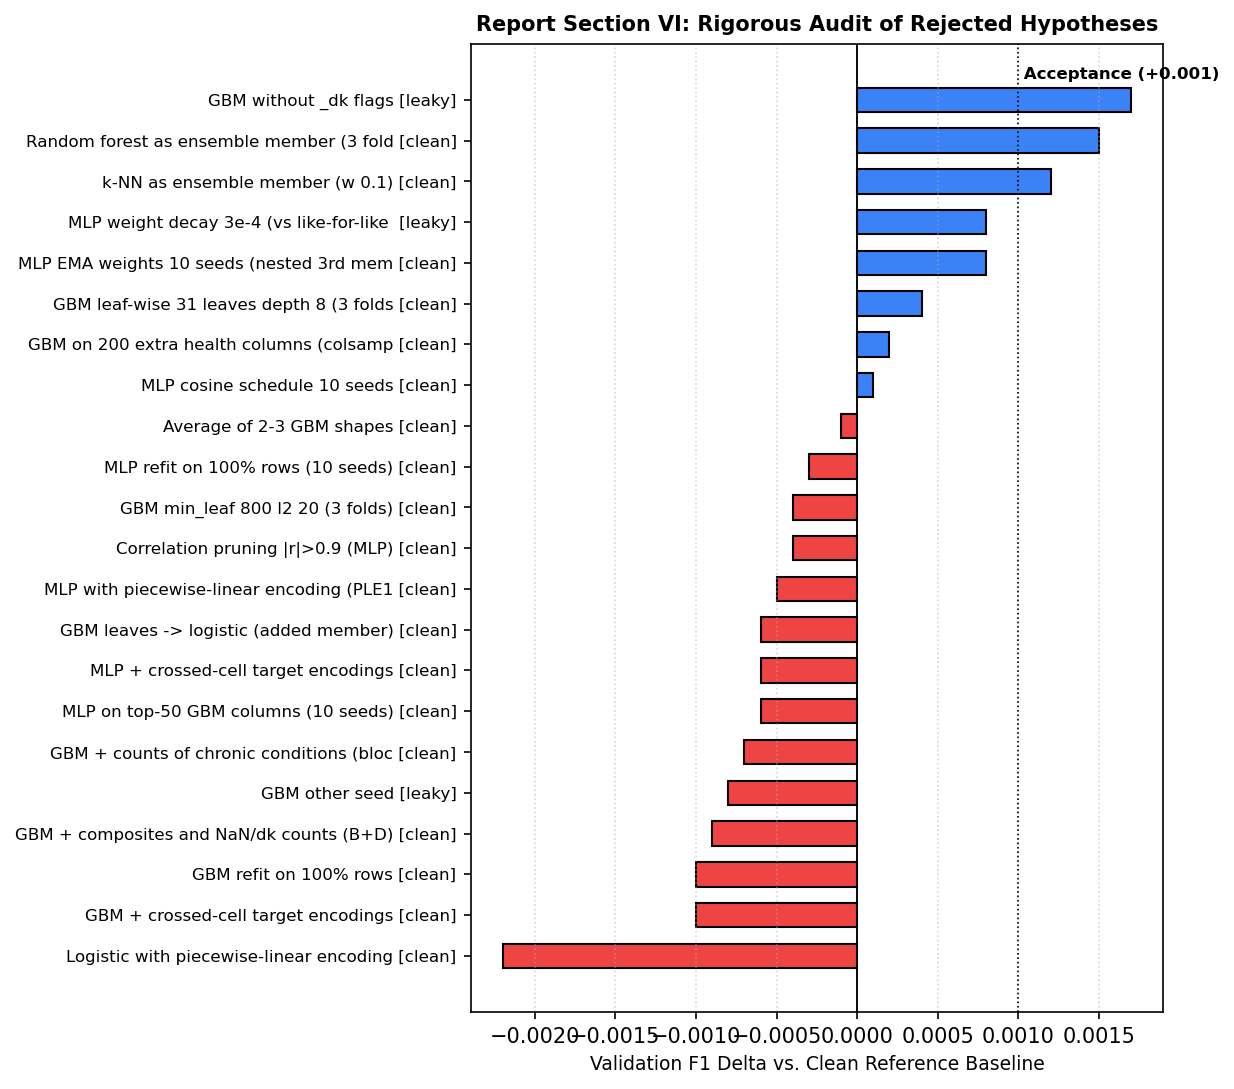

In [1]:
# Display Verified Rejected Experiments from CSV & Plot Impact
import os
import sys
import matplotlib.pyplot as plt

REPO_ROOT = os.path.abspath(".." ) if os.path.exists("../implementations.py") else os.path.abspath(".")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from experiments.plots import load_table, show_table, plot_rejected

rej_rows = load_table("rejected")
show_table("rejected", ["experiment", "variant", "delta_f1", "folds_won"])

fig = plot_rejected(rej_rows)
plt.show()
